# Notebook 03: Feature Engineering
Goal: prepare the input features for price modelling and clustering.

In [136]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/listings_clean.csv")
df.shape

(8075, 90)

In [137]:
features = [
    "neighbourhood_group_cleansed", "room_type", "accommodates",
    "bedrooms", "beds", "bathrooms", "review_scores_rating",
    "number_of_reviews", "host_is_superhost", "minimum_nights",
    "availability_365", "calculated_host_listings_count", "instant_bookable"
]

## 1. Feature selection
I selected 13 features that could actually affect price: location (district),
listing type, size (guests, bedrooms, beds, bathrooms), reviews, host details
and booking rules. Columns such as URLs, descriptions and IDs were left out
because they do not describe the listing in a way a model can use.

In [138]:
df[features].dtypes

neighbourhood_group_cleansed          str
room_type                             str
accommodates                        int64
bedrooms                          float64
beds                              float64
bathrooms                         float64
review_scores_rating              float64
number_of_reviews                   int64
host_is_superhost                     str
minimum_nights                    float64
availability_365                    int64
calculated_host_listings_count      int64
instant_bookable                  float64
dtype: object

In [139]:
df["instant_bookable"].value_counts(dropna=False)

instant_bookable
NaN    8075
Name: count, dtype: int64

In [140]:
features.remove("instant_bookable")

`instant_bookable` was empty for all 8,075 listings in this snapshot,
so it was excluded.

In [141]:
df[features].isnull().sum()

neighbourhood_group_cleansed         0
room_type                            0
accommodates                         0
bedrooms                            12
beds                               256
bathrooms                         8075
review_scores_rating              1253
number_of_reviews                    0
host_is_superhost                    0
minimum_nights                     129
availability_365                     0
calculated_host_listings_count       0
dtype: int64

In [142]:
df["bathrooms_text"].value_counts(dropna=False).head(10)

bathrooms_text
1 bath              4875
1 shared bath        969
1 private bath       777
2 baths              580
1.5 baths            368
2 shared baths        91
1.5 shared baths      90
2.5 baths             58
Shared half-bath      45
0 baths               44
Name: count, dtype: int64

In [143]:
df["bathrooms"] = df["bathrooms_text"].str.extract(r"(\d+\.?\d*)").astype(float)
df.loc[df["bathrooms_text"].str.contains("half", case=False, na=False), "bathrooms"] = 0.5

In [144]:
df["bathroom_shared"] = df["bathrooms_text"].str.contains("shared", case=False, na=False).astype(int)

## 2. Missing values and new features
The "bathrooms" column was empty, but the same information was stored as text
in "bathrooms_text" (e.g. "1.5 shared baths"). I extracted the number of
bathrooms from the text (setting "half-bath" to 0.5) and created a new feature
"bathroom_shared" (1 = shared bathroom), since sharing likely affects price.

In [145]:
df[["bathrooms_text", "bathrooms", "bathroom_shared"]].sample(10)


,bathrooms_text,bathrooms,bathroom_shared
2832,1 bath,1.0,0
7596,1 bath,1.0,0
478,1 bath,1.0,0
916,1 bath,1.0,0
3555,1 bath,1.0,0
5322,2 baths,2.0,0
5059,1 shared bath,1.0,1
5508,1 bath,1.0,0
396,1 shared bath,1.0,1
5641,1 shared bath,1.0,1


In [146]:
df["bathrooms"].isnull().sum()

np.int64(6)

In [147]:
df[df["review_scores_rating"].isnull()]["number_of_reviews"].value_counts().head()

number_of_reviews
0    1253
Name: count, dtype: int64

In [148]:
df["has_reviews"] = (df["number_of_reviews"] > 0).astype(int)
df["review_scores_rating"] = df["review_scores_rating"].fillna(df["review_scores_rating"].median())
features.append("has_reviews")

### Handling missing review scores

- 1,253 listings (about 15%) had no review score. All of them had 0 reviews,
  which means they are new listings that have not been reviewed yet.
- Deleting them would remove 15% of the data, and filling them with the
  average would wrongly suggest these listings are average-rated.
- Instead, I created a new column `has_reviews` (1 = has reviews, 0 = new
  listing) so the model knows which listings are new, and then filled the
  missing scores with the median rating.

In [149]:
df["host_is_superhost"].value_counts(dropna=False)

host_is_superhost
f    5179
t    2896
Name: count, dtype: int64

In [150]:
df["host_is_superhost"] = (df["host_is_superhost"] == "t").astype(int)

"host_is_superhost" was stored as "t"/"f" text, so I converted it to 1/0,
because models only work with numbers.

In [151]:
for col in ["bedrooms", "bathrooms", "beds", "minimum_nights"]:
    df[col] = df[col].fillna(df[col].median())

A few columns still had small gaps: bedrooms (12), bathrooms (6),
minimum_nights (129) and beds (256), all under 4% of listings. I filled them
with the median, because the median is not affected by extreme values the way
the mean is.

In [152]:
df[features].isnull().sum()

neighbourhood_group_cleansed      0
room_type                         0
accommodates                      0
bedrooms                          0
beds                              0
bathrooms                         0
review_scores_rating              0
number_of_reviews                 0
host_is_superhost                 0
minimum_nights                    0
availability_365                  0
calculated_host_listings_count    0
has_reviews                       0
dtype: int64

In [153]:
features = list(dict.fromkeys(features))   # removes duplicates
features.append("bathroom_shared")
features

['neighbourhood_group_cleansed',
 'room_type',
 'accommodates',
 'bedrooms',
 'beds',
 'bathrooms',
 'review_scores_rating',
 'number_of_reviews',
 'host_is_superhost',
 'minimum_nights',
 'availability_365',
 'calculated_host_listings_count',
 'has_reviews',
 'bathroom_shared']

In [154]:
X = pd.get_dummies(
    df[features],
    columns=["neighbourhood_group_cleansed", "room_type"],
    drop_first=True,
    dtype=int
)
X.shape

(8075, 26)

## 3. Encoding categories
District and room type are text categories, so I used one-hot encoding: each
category becomes its own 0/1 column. With `drop_first=True` one category per
feature is left out (e.g. "Entire home/apt"), because it is already implied
when all other columns are 0. This gives 26 numeric features.

In [155]:
X.head()

,accommodates,bedrooms,beds,bathrooms,review_scores_rating,number_of_reviews,host_is_superhost,minimum_nights,availability_365,calculated_host_listings_count,...,neighbourhood_group_cleansed_Neukölln,neighbourhood_group_cleansed_Pankow,neighbourhood_group_cleansed_Reinickendorf,neighbourhood_group_cleansed_Spandau,neighbourhood_group_cleansed_Steglitz - Zehlendorf,neighbourhood_group_cleansed_Tempelhof - Schöneberg,neighbourhood_group_cleansed_Treptow - Köpenick,room_type_Hotel room,room_type_Private room,room_type_Shared room
0,2,1.0,2.0,1.0,4.00,1,0,3.0,351,1,...,0,0,0,0,0,0,0,0,0,0
1,2,1.0,1.0,1.0,4.84,0,0,1.0,256,1,...,0,0,0,0,0,0,0,0,0,0
2,4,2.0,2.0,1.0,5.00,5,0,5.0,323,1,...,1,0,0,0,0,0,0,0,0,0
3,4,1.0,2.0,0.5,4.85,27,0,3.0,290,1,...,0,0,0,0,0,1,0,0,1,0
4,2,1.0,1.0,1.0,5.00,3,0,3.0,250,1,...,0,0,0,0,0,1,0,0,1,0


In [156]:
y = np.log1p(df["price"])

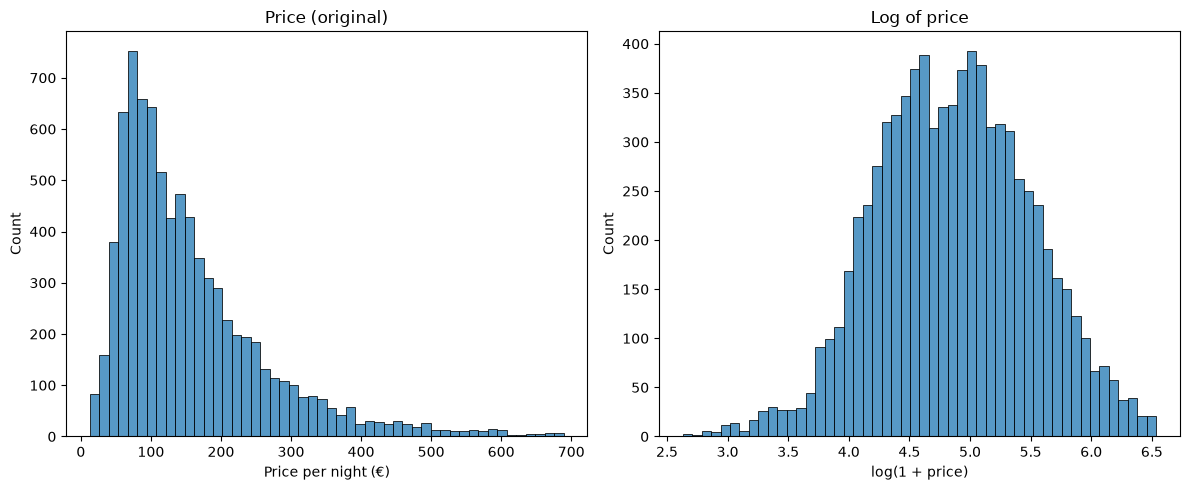

In [157]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df["price"], bins=50, ax=axes[0])
axes[0].set_title("Price (original)")
axes[0].set_xlabel("Price per night (€)")
sns.histplot(y, bins=50, ax=axes[1])
axes[1].set_title("Log of price")
axes[1].set_xlabel("log(1 + price)")
plt.tight_layout()
plt.savefig("../images/05_price_log_transform.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Target transformation
Price is strongly right-skewed. I modelled log(1 + price) instead, which makes
the distribution close to symmetric and helps regression models. Predictions
will be converted back to euros for interpretation.

## 5. Correlation with price

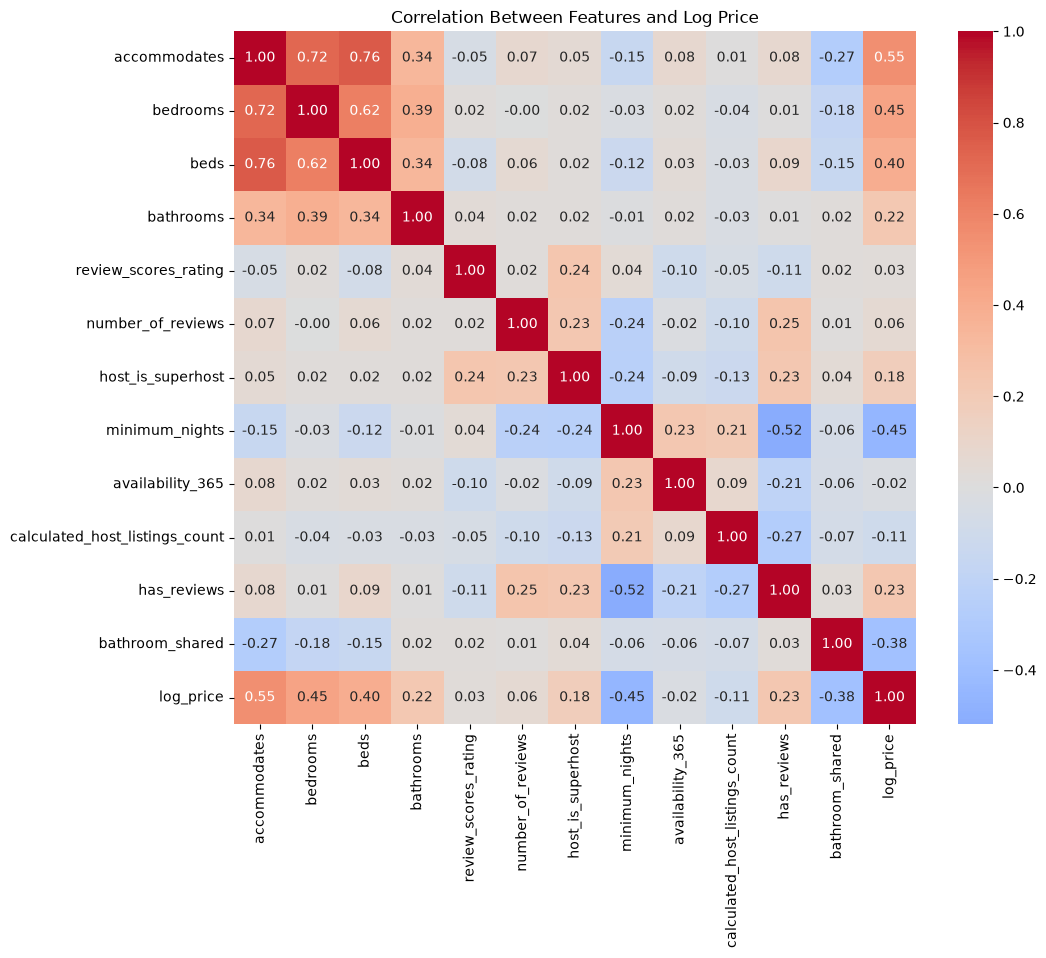

In [158]:
num_cols = ["accommodates", "bedrooms", "beds", "bathrooms", "review_scores_rating",
            "number_of_reviews", "host_is_superhost", "minimum_nights",
            "availability_365", "calculated_host_listings_count", "has_reviews", "bathroom_shared"]

corr = pd.concat([df[num_cols], y.rename("log_price")], axis=1).corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Features and Log Price")
plt.savefig("../images/06_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [159]:
corr["log_price"].sort_values(ascending=False)

log_price                         1.000000
accommodates                      0.552535
bedrooms                          0.452534
beds                              0.397568
has_reviews                       0.233757
bathrooms                         0.217061
host_is_superhost                 0.178801
number_of_reviews                 0.057347
review_scores_rating              0.030802
availability_365                 -0.023422
calculated_host_listings_count   -0.107420
bathroom_shared                  -0.379681
minimum_nights                   -0.448904
Name: log_price, dtype: float64

In [160]:
df["minimum_nights"].describe()


count    8075.000000
mean       19.381548
std        37.278736
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       365.000000
Name: minimum_nights, dtype: float64

In [161]:
(df["minimum_nights"] >= 30).mean()

np.float64(0.18736842105263157)

In [162]:
df.groupby(df["minimum_nights"] >= 30)["price"].median()

minimum_nights
False    147.50
True      66.12
Name: price, dtype: float64

In [163]:
X["long_stay"] = (df["minimum_nights"] >= 30).astype(int)

### What the correlations show

- The size features have the strongest positive link with log price:
  accommodates (0.55), bedrooms (0.45) and beds (0.40). These three 
  overlap strongly with each other (0.62–0.76), because they together describe
  the size of the listing.
- Minimum nights has a strong negative link (−0.45). 18.7% of listings
  require a stay of 30 nights or more, and their median price is €66 per
  night, compared to €148 for short stays. This is likely related to
  Berlin's rules on short-term holiday rentals, which push many hosts
  towards longer stays. I therefore added a "long_stay" feature
  (1 = minimum 30+ nights).
- Shared bathrooms are linked to lower prices (−0.38), while review scores
  have almost no link with price on their own (0.03).
- These are simple one-to-one comparisons. The regression model will show
  whether these effects remain when all features are considered together.

In [164]:
X["long_stay"] = (df["minimum_nights"] >= 30).astype(int)
X.shape

(8075, 27)

## 6. Save model-ready data

In [165]:
model_df = X.copy()
model_df["log_price"] = y
model_df["price"] = df["price"]
model_df.to_csv("../data/listings_model.csv", index=False)
model_df.shape

(8075, 29)